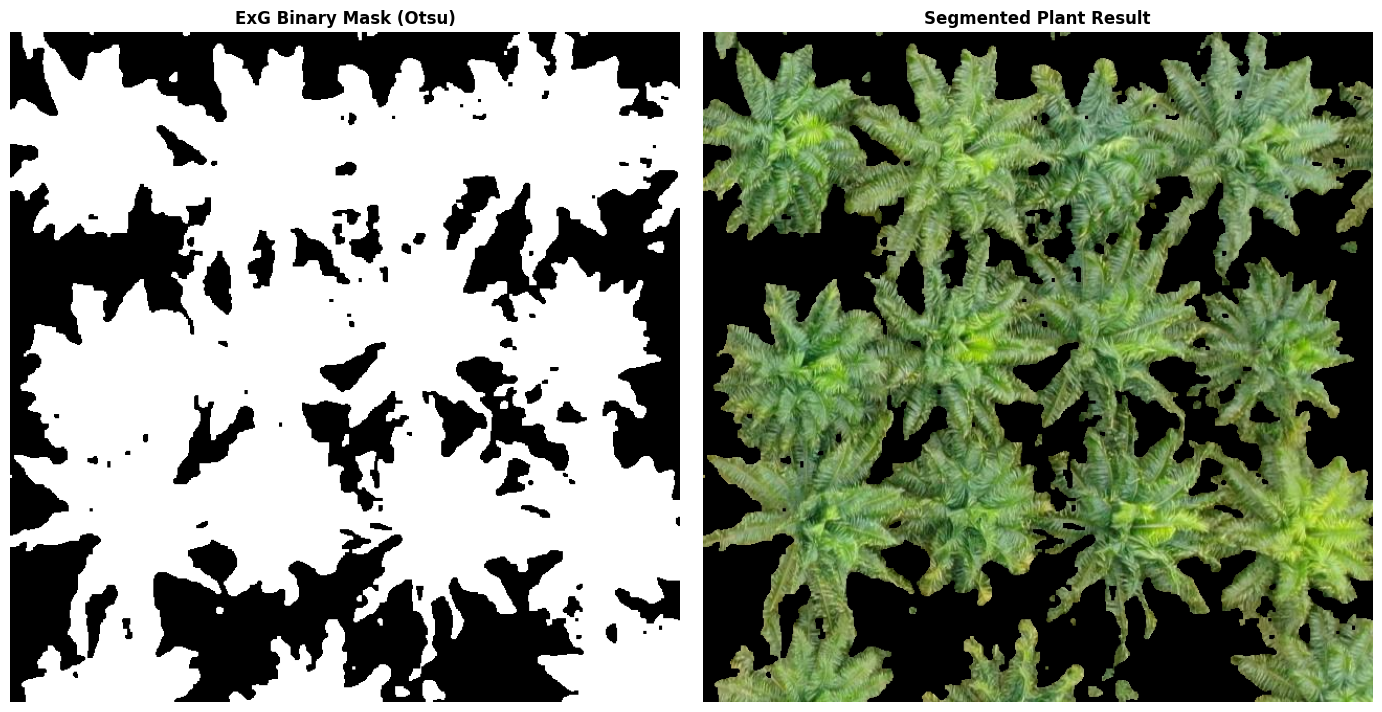

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Model input feature name: 'image'
Running inference...
Raw tensor shape: (1, 5, 8400)
Detected palms after NMS: 15


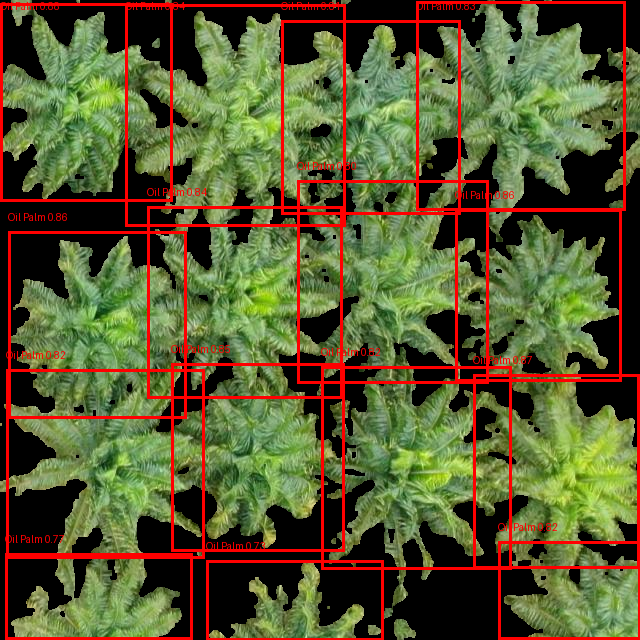

Box: [0, 0.00546875, 0.26904296875, 0.314453125], Score: 0.8760
Box: [0.7392578125, 0.5857421875, 0.9998046875, 0.8884765625], Score: 0.8711
Box: [0.711328125, 0.3275390625, 0.971484375, 0.5958984375], Score: 0.8647
Box: [0.0134765625, 0.36201171875, 0.2912109375, 0.65361328125], Score: 0.8574
Box: [0.26767578125, 0.5685546875, 0.53779296875, 0.8619140625], Score: 0.8540
Box: [0.19638671875, 0.00625, 0.53955078125, 0.3541015625], Score: 0.8433
Box: [0.230078125, 0.32216796875, 0.535546875, 0.62236328125], Score: 0.8359
Box: [0.65, 0.0017578125, 0.9765625, 0.3291015625], Score: 0.8296
Box: [0.77890625, 0.845703125, 1, 0.999609375], Score: 0.8223
Box: [0.0107421875, 0.5771484375, 0.3193359375, 0.8728515625], Score: 0.8218
Box: [0.502734375, 0.5724609375, 0.799609375, 0.8900390625], Score: 0.8164
Box: [0.440234375, 0.03134765625, 0.719140625, 0.33583984375], Score: 0.8135
Box: [0.465234375, 0.28232421875, 0.763671875, 0.59892578125], Score: 0.7954
Box: [0.0083984375, 0.864453125, 0.300976

#,Confidence Score,Cropped Oil Palm
1,0.8760,
2,0.8711,
3,0.8647,
4,0.8574,
5,0.8540,
6,0.8433,
7,0.8359,
8,0.8296,
9,0.8223,
10,0.8218,

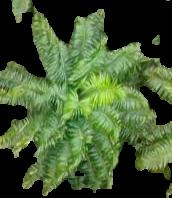
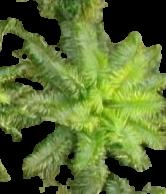
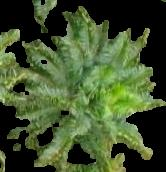
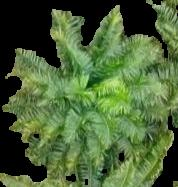
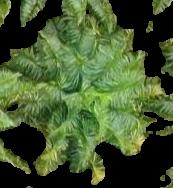
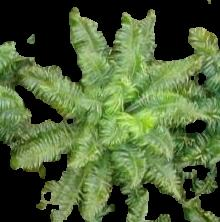
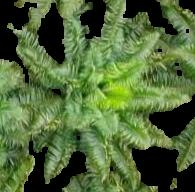
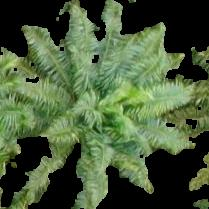
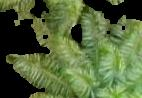
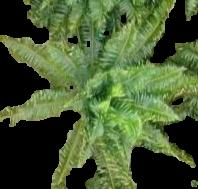
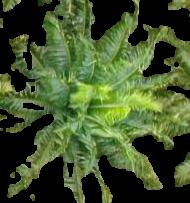
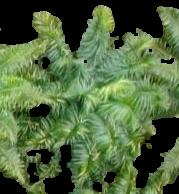
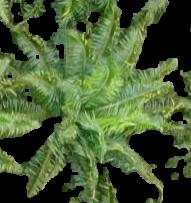
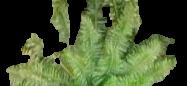
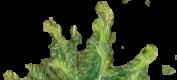

In [8]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "DJI_15-copy_jpg.rf.947a177207587775a6d0377b1173ca20.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# ExG Segmentation Function
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    # Load the image (OpenCV loads as BGR)
    image_bgr = cv2.imread(image_path)
    
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    # Extract channels and compute ExG index
    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    # Normalize to an 8-bit range (0-255)
    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    # Apply Otsu's thresholding & morphological noise cleanup
    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    # Isolate plants from background
    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)

    return binary_mask, segmented_plant


# --------------------------------------------------
# Step 1: Run ExG Segmentation & Plot Inline
# --------------------------------------------------

binary_mask, segmented_result = segment_vegetation_exg(IMAGE_PATH)
segmented_rgb = cv2.cvtColor(segmented_result, cv2.COLOR_BGR2RGB)

fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(binary_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')

axes[1].imshow(segmented_rgb)
axes[1].set_title("Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')

plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on Segmented Image
# --------------------------------------------------
try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    
    # Fix: Iterate over input_description instead of calling .keys()
    input_name = list(model.input_description)[0]
    print(f"Model input feature name: '{input_name}'")
    
    image = Image.fromarray(segmented_rgb).convert("RGB")
    original_width, original_height = image.size

    # Resize image to match model input requirement (640x640)
    input_image = image.resize((640, 640))

    print(f"Running inference...")
    prediction = model.predict({input_name: input_image})
    
    # Extract raw output tensor dynamically
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])
    print(f"Raw tensor shape: {raw.shape}")

    # Parse [1, 5, 8400] -> [8400, 5]
    predictions = raw[0].T
    boxes = []
    scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred

        if confidence < CONF_THRESHOLD:
            continue

        # xywh -> normalized xyxy coordinates (0..1)
        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        boxes.append([
            max(0, min(1, x1)),
            max(0, min(1, y1)),
            max(0, min(1, x2)),
            max(0, min(1, y2))
        ])
        scores.append(float(confidence))

    # Apply Non-Maximum Suppression (NMS)
    if boxes:
        selected = nms(boxes, scores, IOU_THRESHOLD)
        boxes = [boxes[i] for i in selected]
        scores = [scores[i] for i in selected]

    print(f"Detected palms after NMS: {len(boxes)}")

    # --------------------------------------------------
    # Step 3: Draw Bounding Boxes and Display Inline
    # --------------------------------------------------
    detector_image = image.copy()
    draw = ImageDraw.Draw(detector_image)

    for box, score in zip(boxes, scores):
        x1, y1, x2, y2 = box

        # Convert normalized coordinates back to original image scale
        px1 = int(x1 * original_width)
        py1 = int(y1 * original_height)
        px2 = int(x2 * original_width)
        py2 = int(y2 * original_height)

        # Draw red bounding box
        draw.rectangle([px1, py1, px2, py2], outline="red", width=3)

        # Draw confidence label
        draw.text((px1, max(0, py1 - 20)), f"Oil Palm {score:.2f}", fill="red")

    display(detector_image)

    for box, score in zip(boxes, scores):
        print(f"Box: {box}, Score: {score:.4f}")

    # --------------------------------------------------
    # Step 4: Crop each Detection and Show in an HTML Table
    # --------------------------------------------------
    print(f"\n--- Cropped Detections Table ({len(boxes)} items) ---")
    
    html_content = """
    <table style="border-collapse: collapse; width: 100%; text-align: center;">
        <tr style="background-color: #f2f2f2; border-bottom: 2px solid #ddd;">
            <th style="padding: 8px; border: 1px solid #ddd;">#</th>
            <th style="padding: 8px; border: 1px solid #ddd;">Confidence Score</th>
            <th style="padding: 8px; border: 1px solid #ddd;">Cropped Oil Palm</th>
        </tr>
    """

    for idx, (box, score) in enumerate(zip(boxes, scores)):
        x1, y1, x2, y2 = box
        px1 = int(x1 * original_width)
        py1 = int(y1 * original_height)
        px2 = int(x2 * original_width)
        py2 = int(y2 * original_height)

        # Crop the bounding box region from the image
        cropped_img = image.crop((px1, py1, px2, py2))

        # Convert cropped PIL image to base64 string to embed in HTML
        buffered = io.BytesIO()
        cropped_img.save(buffered, format="JPEG")
        img_str = base64.b64encode(buffered.getvalue()).decode()

        html_content += f"""
        <tr style="border-bottom: 1px solid #ddd;">
            <td style="padding: 8px; border: 1px solid #ddd; font-weight: bold;">{idx + 1}</td>
            <td style="padding: 8px; border: 1px solid #ddd;">{score:.4f}</td>
            <td style="padding: 8px; border: 1px solid #ddd;"><img src="data:image/jpeg;base64,{img_str}" style="max-height: 120px; border-radius: 4px;"/></td>
        </tr>
        """

    html_content += "</table>"
    display(HTML(html_content))

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")

Running ExG Segmentation...


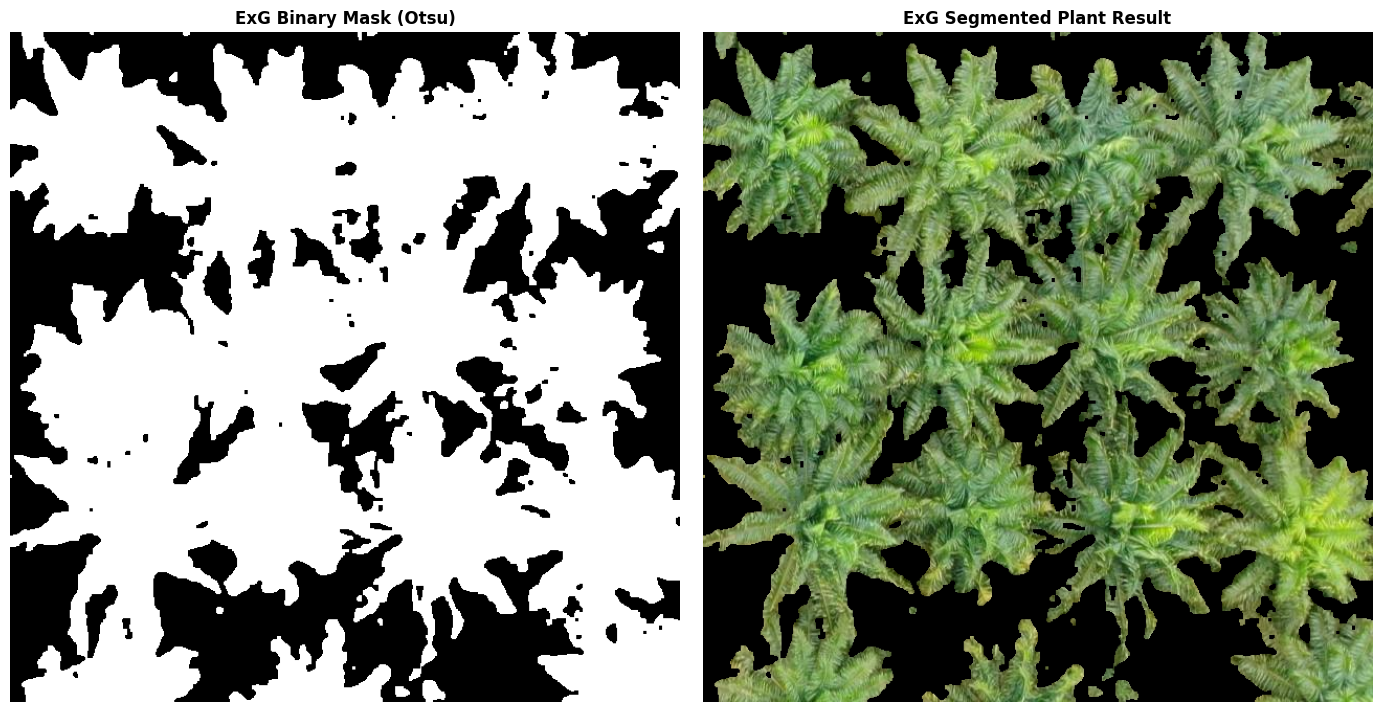

Loading CoreML model from yolo26m-krops-v0.1.mlpackage...
Running inference on ExG segmented image...
Saved 15 valid detection boxes from ExG inference.

Calculating VARI heatmap on the ExG segmented image...


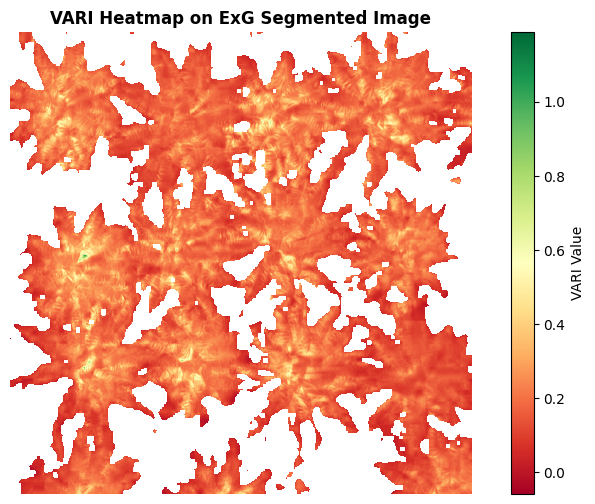


--- ExG-Segmented Output with Bounding Boxes ---


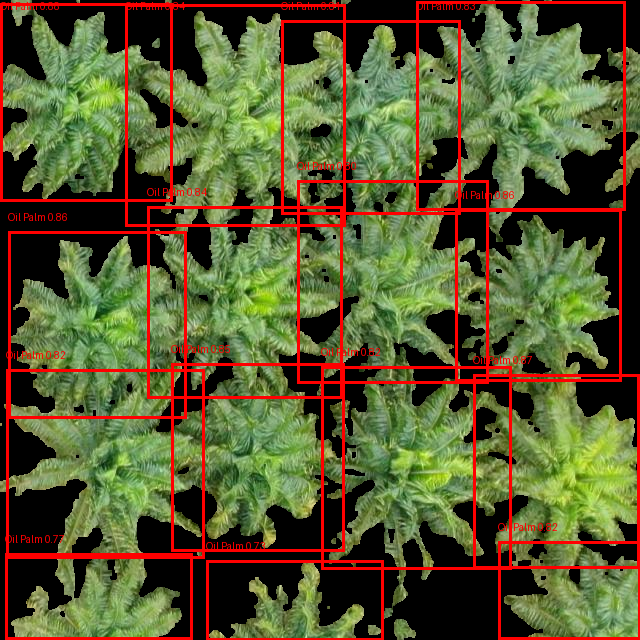


--- Cropped Detections Table (15 items) ---


#,Confidence Score,Cropped Oil Palm (ExG + VARI Context)
1,0.8760,
2,0.8711,
3,0.8647,
4,0.8574,
5,0.8540,
6,0.8433,
7,0.8359,
8,0.8296,
9,0.8223,
10,0.8218,

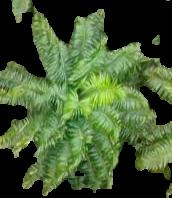
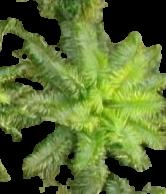
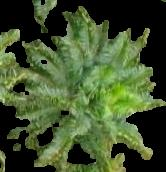
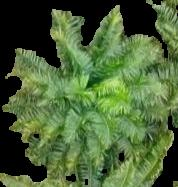
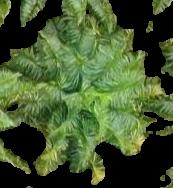
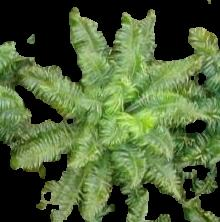
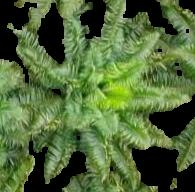
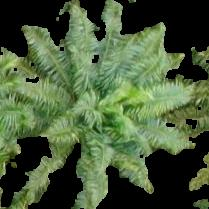
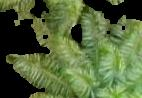
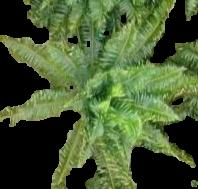
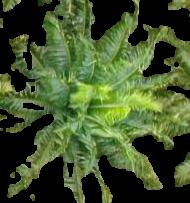
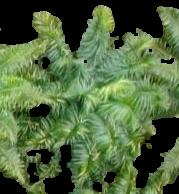
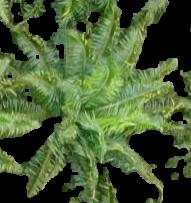
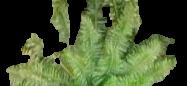
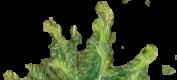

In [11]:
import cv2
import numpy as np
import coremltools as ct
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import io
import base64
from IPython.display import HTML, display

IMAGE_PATH = "DJI_15-copy_jpg.rf.947a177207587775a6d0377b1173ca20.jpg"
MODEL_PATH = "yolo26m-krops-v0.1.mlpackage"

CONF_THRESHOLD = 0.25
IOU_THRESHOLD = 0.45


# --------------------------------------------------
# Helper Functions: IoU and NMS
# --------------------------------------------------

def iou(box1, box2):
    x1 = max(box1[0], box2[0])
    y1 = max(box1[1], box2[1])
    x2 = min(box1[2], box2[2])
    y2 = min(box1[3], box2[3])

    inter_w = max(0, x2 - x1)
    inter_h = max(0, y2 - y1)
    inter_area = inter_w * inter_h

    area1 = max(0, box1[2] - box1[0]) * max(0, box1[3] - box1[1])
    area2 = max(0, box2[2] - box2[0]) * max(0, box2[3] - box2[1])

    union = area1 + area2 - inter_area
    return inter_area / union if union > 0 else 0


def nms(boxes, scores, iou_threshold=0.45):
    order = np.argsort(scores)[::-1]
    selected = []

    while len(order) > 0:
        i = order[0]
        selected.append(i)
        remaining = []

        for j in order[1:]:
            if iou(boxes[i], boxes[j]) <= iou_threshold:
                remaining.append(j)

        order = np.array(remaining)

    return selected


# --------------------------------------------------
# Step 1: Run ExG Segmentation
# --------------------------------------------------

def segment_vegetation_exg(image_path):
    image_bgr = cv2.imread(image_path)
    if image_bgr is None:
        raise ValueError(f"Could not load image from {image_path}. Check the path.")

    b, g, r = cv2.split(image_bgr)
    exg = (2 * g.astype(np.float32)) - r.astype(np.float32) - b.astype(np.float32)

    exg_normalized = cv2.normalize(exg, None, alpha=0, beta=255, norm_type=cv2.NORM_MINMAX)
    exg_uint8 = np.clip(exg_normalized, 0, 255).astype(np.uint8)

    _, binary_mask = cv2.threshold(exg_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    kernel = np.ones((3, 3), np.uint8)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_OPEN, kernel, iterations=1)
    binary_mask = cv2.morphologyEx(binary_mask, cv2.MORPH_CLOSE, kernel, iterations=1)

    segmented_plant = cv2.bitwise_and(image_bgr, image_bgr, mask=binary_mask)
    return binary_mask, segmented_plant, image_bgr

print("Running ExG Segmentation...")
exg_mask, exg_segmented_bgr, original_bgr = segment_vegetation_exg(IMAGE_PATH)
exg_rgb = cv2.cvtColor(exg_segmented_bgr, cv2.COLOR_BGR2RGB)
original_height, original_width = original_bgr.shape[:2]

# Plot ExG Inline
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
axes[0].imshow(exg_mask, cmap='gray')
axes[0].set_title("ExG Binary Mask (Otsu)", fontsize=12, fontweight='bold')
axes[0].axis('off')
axes[1].imshow(exg_rgb)
axes[1].set_title("ExG Segmented Plant Result", fontsize=12, fontweight='bold')
axes[1].axis('off')
plt.tight_layout()
plt.show()


# --------------------------------------------------
# Step 2: Run CoreML Detection on ExG Output & Save Boxes
# --------------------------------------------------

saved_boxes = []
saved_scores = []

try:
    print(f"Loading CoreML model from {MODEL_PATH}...")
    model = ct.models.MLModel(MODEL_PATH)
    input_name = list(model.input_description)[0]
    
    image_exg_pil = Image.fromarray(exg_rgb).convert("RGB")
    input_image = image_exg_pil.resize((640, 640))

    print("Running inference on ExG segmented image...")
    prediction = model.predict({input_name: input_image})
    
    output_key = list(prediction.keys())[0]
    raw = np.asarray(prediction[output_key])

    predictions = raw[0].T
    temp_boxes = []
    temp_scores = []

    for pred in predictions:
        cx, cy, w, h, confidence = pred
        if confidence < CONF_THRESHOLD:
            continue

        x1 = (cx - w / 2) / 640
        y1 = (cy - h / 2) / 640
        x2 = (cx + w / 2) / 640
        y2 = (cy + h / 2) / 640

        temp_boxes.append([max(0, min(1, x1)), max(0, min(1, y1)), max(0, min(1, x2)), max(0, min(1, y2))])
        temp_scores.append(float(confidence))

    if temp_boxes:
        selected = nms(temp_boxes, temp_scores, IOU_THRESHOLD)
        saved_boxes = [temp_boxes[i] for i in selected]
        saved_scores = [temp_scores[i] for i in selected]

    print(f"Saved {len(saved_boxes)} valid detection boxes from ExG inference.")

except Exception as e:
    print(f"\n[Execution Note]: {e}")
    print("Tip: CoreML native prediction (`model.predict()`) requires running inside a macOS environment.")


# --------------------------------------------------
# Step 3: Calculate VARI Heatmap *on the ExG Segmented Image*
# --------------------------------------------------

print("\nCalculating VARI heatmap on the ExG segmented image...")

# Split channels from the ExG-segmented BGR image
b_exg, g_exg, r_exg = cv2.split(exg_segmented_bgr)
b_f = b_exg.astype(np.float32)
g_f = g_exg.astype(np.float32)
r_f = r_exg.astype(np.float32)

# VARI formula: (Green - Red) / (Green + Red - Blue)
denominator = g_f + r_f - b_f
denominator = np.where(denominator == 0, 1e-6, denominator)
vari_map = (g_f - r_f) / denominator

# Mask out the background (where ExG mask was 0) so VARI only shows on isolated plants
vari_map = np.where(exg_mask == 0, np.nan, vari_map)

# Plot VARI Heatmap inline
plt.figure(figsize=(10, 6))
plt.imshow(vari_map, cmap='RdYlGn')
plt.colorbar(label='VARI Value')
plt.title("VARI Heatmap on ExG Segmented Image", fontsize=12, fontweight='bold')
plt.axis('off')
plt.show()


# --------------------------------------------------
# Step 4: Apply Saved Bounding Boxes to VARI Output Image
# --------------------------------------------------

# Convert ExG-segmented result to PIL for drawing and cropping
vari_source_image = Image.fromarray(exg_rgb).convert("RGB")
detector_image = vari_source_image.copy()
draw = ImageDraw.Draw(detector_image)

for box, score in zip(saved_boxes, saved_scores):
    x1, y1, x2, y2 = box
    px1 = int(x1 * original_width)
    py1 = int(y1 * original_height)
    px2 = int(x2 * original_width)
    py2 = int(y2 * original_height)

    draw.rectangle([px1, py1, px2, py2], outline="red", width=3)
    draw.text((px1, max(0, py1 - 20)), f"Oil Palm {score:.2f}", fill="red")

print("\n--- ExG-Segmented Output with Bounding Boxes ---")
display(detector_image)


# --------------------------------------------------
# Step 5: Crop each Detection and Show in HTML Table
# --------------------------------------------------

print(f"\n--- Cropped Detections Table ({len(saved_boxes)} items) ---")

html_content = """
<table style="border-collapse: collapse; width: 100%; text-align: center;">
    <tr style="background-color: #f2f2f2; border-bottom: 2px solid #ddd;">
        <th style="padding: 8px; border: 1px solid #ddd;">#</th>
        <th style="padding: 8px; border: 1px solid #ddd;">Confidence Score</th>
        <th style="padding: 8px; border: 1px solid #ddd;">Cropped Oil Palm (ExG + VARI Context)</th>
    </tr>
"""

for idx, (box, score) in enumerate(zip(saved_boxes, saved_scores)):
    x1, y1, x2, y2 = box
    px1 = int(x1 * original_width)
    py1 = int(y1 * original_height)
    px2 = int(x2 * original_width)
    py2 = int(y2 * original_height)

    cropped_img = vari_source_image.crop((px1, py1, px2, py2))

    buffered = io.BytesIO()
    cropped_img.save(buffered, format="JPEG")
    img_str = base64.b64encode(buffered.getvalue()).decode()

    html_content += f"""
    <tr style="border-bottom: 1px solid #ddd;">
        <td style="padding: 8px; border: 1px solid #ddd; font-weight: bold;">{idx + 1}</td>
        <td style="padding: 8px; border: 1px solid #ddd;">{score:.4f}</td>
        <td style="padding: 8px; border: 1px solid #ddd;"><img src="data:image/jpeg;base64,{img_str}" style="max-height: 120px; border-radius: 4px;"/></td>
    </tr>
    """

html_content += "</table>"
display(HTML(html_content))


In [ ]:
#